In [8]:
import sounddevice as sd
import soundfile as sf
from src.audio_device import AudioDevice
from src.sharc import Sharc
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print(sd.query_devices())

   0 Microsoft Sound Mapper - Input, MME (2 in, 0 out)
>  1 Microphone Array (Intel® Smart , MME (4 in, 0 out)
   2 Microsoft Sound Mapper - Output, MME (0 in, 2 out)
   3 Speakers (Realtek(R) Audio), MME (0 in, 2 out)
<  4 Primary Sound Capture Driver, Windows DirectSound (2 in, 0 out)
   5 Microphone Array (Intel® Smart Sound Technology (Intel® SST)), Windows DirectSound (4 in, 0 out)
   6 Primary Sound Driver, Windows DirectSound (0 in, 2 out)
   7 Speakers (Realtek(R) Audio), Windows DirectSound (0 in, 2 out)
   8 Speakers (Realtek(R) Audio), Windows WASAPI (0 in, 2 out)
   9 Microphone Array (Intel® Smart Sound Technology (Intel® SST)), Windows WASAPI (2 in, 0 out)
  10 Microphone Array 1 (Intel® Smart Sound Technology (Intel® SST) Microphone), Windows WDM-KS (2 in, 0 out)
  11 Microphone Array 2 (Intel® Smart Sound Technology (Intel® SST) Microphone), Windows WDM-KS (4 in, 0 out)
  12 Microphone Array 3 (Intel® Smart Sound Technology (Intel® SST) Microphone), Windows WDM-KS (4 in

In [9]:
fs = 96_000
ad = AudioDevice(fs, in_device=1, out_device=4)

In [10]:
f1, f2 = 300, 1000
amp1, amp2 = 0.25, 0.25
repeats = 3

# Each condition: 1 s to settle, 1 s to analyze, 1 s of silence.
# All slots start on the same phase for these integer-Hz tones.
tone_n = 2 * fs
slot_n = 3 * fs
t = np.arange(tone_n) / fs

fade_n = round(0.02 * fs)
env = np.ones(tone_n)
ramp = np.sin(np.linspace(0, np.pi / 2, fade_n)) ** 2
env[:fade_n], env[-fade_n:] = ramp, ramp[::-1]

a = (amp1 * env * np.sin(2 * np.pi * f1 * t)).astype(np.float32)
b = (amp2 * env * np.sin(2 * np.pi * f2 * t)).astype(np.float32)

from datetime import datetime
from pathlib import Path

save_dir = Path("data/two_tone_imd") / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
save_dir.mkdir(parents=True)

tests = {
    "split_speakers": [
        ("silence",   None, None),
        ("panel_f1",  a,    None),
        ("source_f2", None, b),
        ("split_both", a,   b),
    ],
    "panel_only": [
        ("silence",    None,  None),
        ("panel_f1",   a,     None),
        ("panel_f2",   b,     None),
        ("panel_both", a + b, None),
    ],
}

saved_paths = {name: [] for name in tests}

for trial in range(1, repeats + 1):
    # Alternate which test goes first across repeats.
    test_order = list(tests) if trial % 2 else list(reversed(tests))

    for test_name in test_order:
        slots = tests[test_name]
        left = np.zeros(len(slots) * slot_n, dtype=np.float32)
        right = np.zeros_like(left)

        for i, (_, panel, source) in enumerate(slots):
            sl = slice(i * slot_n, i * slot_n + tone_n)
            if panel is not None:
                left[sl] = panel
            if source is not None:
                right[sl] = source

        assert max(np.max(np.abs(left)), np.max(np.abs(right))) < 1.0
        error_mic, reference_mic = ad.play(left=left, right=right, blocking=True)

        path = save_dir / f"{test_name}_trial{trial:02d}.npz"
        np.savez_compressed(
            path,
            test=test_name, trial=trial,
            order=np.array([name for name, _, _ in slots]),
            error_mic=error_mic, reference_mic=reference_mic,
            panel_drive=left, source_drive=right,
            fs=fs, f1=f1, f2=f2, amp1=amp1, amp2=amp2,
            tone_n=tone_n, slot_n=slot_n, fade_n=fade_n,
            analysis_offset=round(0.75 * fs), analysis_n=fs,
        )
        saved_paths[test_name].append(path)
        print(f"Saved {path.name}  |  error mic peak {np.max(np.abs(error_mic)):.3f}")

print(save_dir.resolve())

PortAudioError: Error opening Stream: Illegal combination of I/O devices [PaErrorCode -9993]

## Load saved recordings and analyze
Run every cell from here downward after acquisition. After a kernel restart, you can start here without initializing audio hardware. The loader uses `save_dir` when available, otherwise the newest saved run. Set `analysis_dir` below to select a different run.


In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Leave None to use this session's save_dir, or the latest saved run after a restart.
# To select a specific run, set e.g. Path("data/two_tone_imd/20261106_...").
analysis_dir = Path("data/two_tone_imd/20261105_134040_440763")
mic_key = "error_mic"  # Change to "reference_mic" to analyze the other input.

if analysis_dir is not None:
    run_dir = Path(analysis_dir)
elif "save_dir" in globals():
    run_dir = Path(save_dir)
else:
    root = Path("data/two_tone_imd")
    runs = sorted(p for p in root.glob("*") if p.is_dir() and any(p.glob("*_trial*.npz")))
    if not runs:
        raise FileNotFoundError("No saved trials found. Set analysis_dir to your recording folder.")
    run_dir = runs[-1]

if not run_dir.is_dir():
    raise FileNotFoundError(f"Recording folder does not exist: {run_dir}")
print(f"Loading recordings from {run_dir.resolve()}")

# (simultaneous condition, first solo, second solo)
conditions = {
    "split_speakers": ("split_both", "panel_f1", "source_f2"),
    "panel_only":     ("panel_both", "panel_f1", "panel_f2"),
}
titles = {"split_speakers": "Split speakers", "panel_only": "Panel only"}

spectra = {}
run_settings = None

for test, (both, solo1, solo2) in conditions.items():
    paths = sorted(run_dir.glob(f"{test}_trial*.npz"))
    if len(paths) < 2:
        raise ValueError(f"Found {len(paths)} {test} trials; need at least 2 for repeat uncertainty.")

    trials = []
    for path in paths:
        with np.load(path, allow_pickle=False) as d:
            fs = int(d["fs"])
            n = int(d["analysis_n"])
            offset = int(d["analysis_offset"])
            slot_n = int(d["slot_n"])
            f1, f2 = float(d["f1"]), float(d["f2"])
            settings = (fs, n, offset, f1, f2, float(d["amp1"]), float(d["amp2"]))
            if run_settings is None:
                run_settings = settings
            elif settings != run_settings:
                raise ValueError(f"Acquisition settings differ in {path.name}")

            if str(d["test"].item()) != test:
                raise ValueError(f"Test name mismatch in {path.name}")
            order = d["order"].tolist()
            required = ["silence", both, solo1, solo2]
            if any(order.count(name) != 1 for name in required):
                raise ValueError(f"Missing or duplicate conditions in {path.name}")
            mic = d[mic_key]
            if len(mic) != slot_n * len(order) or offset < 0 or n < 1 or offset + n > int(d["tone_n"]):
                raise ValueError(f"Unexpected recording length or window in {path.name}")

            # Same sample offset in all four slots; preserve measured phase.
            waves = {}
            for i, name in enumerate(order):
                start = i * slot_n + offset
                waves[name] = mic[start:start + n].astype(np.float64)

        measured = waves[both]
        predicted = waves[solo1] + waves[solo2] - waves["silence"]
        trials.append({
            "both": measured,
            "predicted": predicted,
            "residual": measured - predicted,
            "solo1": waves[solo1],
            "solo2": waves[solo2],
        })

    # Each entry has shape (trials, frequency bins).
    spectra[test] = {}
    for key in trials[0]:
        waves = np.stack([trial[key] for trial in trials])
        z = np.fft.rfft(waves, axis=1) * (2.0 / n)
        z[:, 0] *= 0.5
        if n % 2 == 0:
            z[:, -1] *= 0.5
        spectra[test][key] = z

    print(f"{titles[test]}: {len(trials)} trials")

freq = np.fft.rfftfreq(n, d=1 / fs)

def dbfs(z):
    return 20 * np.log10(np.maximum(np.abs(z), 1e-15))

def repeat_se(z):
    # RMS scatter of complex FFT coefficients, scaled to uncertainty of the mean.
    return z.std(axis=0, ddof=1) / np.sqrt(z.shape[0])

products = sorted([
    ("|2f₁−f₂|", abs(2*f1 - f2)),
    ("|f₂−f₁|",  abs(f2 - f1)),
    ("f₁+f₂",    f1 + f2),
    ("2f₁+f₂",   2*f1 + f2),
    ("|2f₂−f₁|", abs(2*f2 - f1)),
    ("2f₂+f₁",   2*f2 + f1),
], key=lambda item: item[1])

Loading recordings from C:\Users\rnbow\Desktop\Projects\Reverb-Control\experiments\data\two_tone_imd\20261105_134040_440763
Split speakers: 3 trials
Panel only: 3 trials


## Spectra
Top: simultaneous playback versus the sum of solo recordings (minus silence). Bottom: the residual for each repeat in gray and its complex mean in purple. Subtraction occurs before taking FFT magnitudes. Separate play calls can have different recording phases; the individual-repeat curves help reveal cancellation in the complex mean.


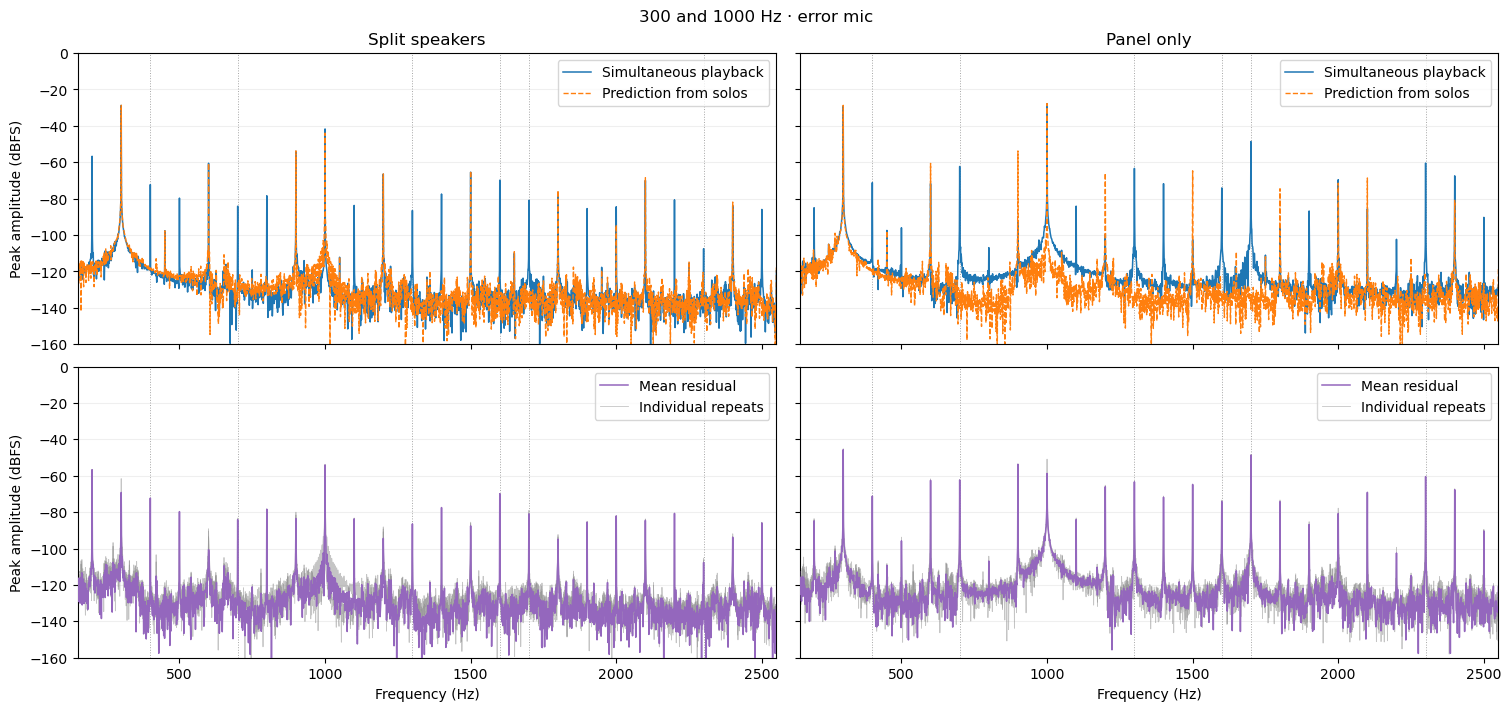

In [17]:
fig, axes = plt.subplots(
    2, 2, figsize=(15, 7), sharex=True, sharey=True, constrained_layout=True
)

fmin, fmax = 150, max(hz for _, hz in products) + 250
band = (freq >= fmin) & (freq <= fmax)

for col, (test, s) in enumerate(spectra.items()):
    top, bottom = axes[:, col]
    r = s["residual"]

    top.plot(freq[band], dbfs(s["both"].mean(axis=0)[band]),
             lw=1.1, label="Simultaneous playback")
    top.plot(freq[band], dbfs(s["predicted"].mean(axis=0)[band]),
             lw=1, ls="--", color="tab:orange", label="Prediction from solos")
    top.set_title(titles[test])

    bottom.plot(freq[band], dbfs(r.mean(axis=0)[band]),
                lw=1.1, color="tab:purple", label="Mean residual", zorder=3)
    for trial_index, trial_spectrum in enumerate(r):
        bottom.plot(freq[band], dbfs(trial_spectrum[band]),
                    lw=0.6, color="0.55", alpha=0.5,
                    label="Individual repeats" if trial_index == 0 else None)
    bottom.set_xlabel("Frequency (Hz)")

    for ax in (top, bottom):
        for _, hz in products:
            ax.axvline(hz, color="0.65", ls=":", lw=0.7, zorder=0)
        ax.set_xlim(fmin, fmax)
        ax.set_ylim(-160, 0)
        ax.grid(axis="y", alpha=0.2)
        ax.legend(loc="upper right")

axes[0, 0].set_ylabel("Peak amplitude (dBFS)")
axes[1, 0].set_ylabel("Peak amplitude (dBFS)")
fig.suptitle(f"{f1:g} and {f2:g} Hz · {mic_key.replace('_', ' ')}")
plt.show()

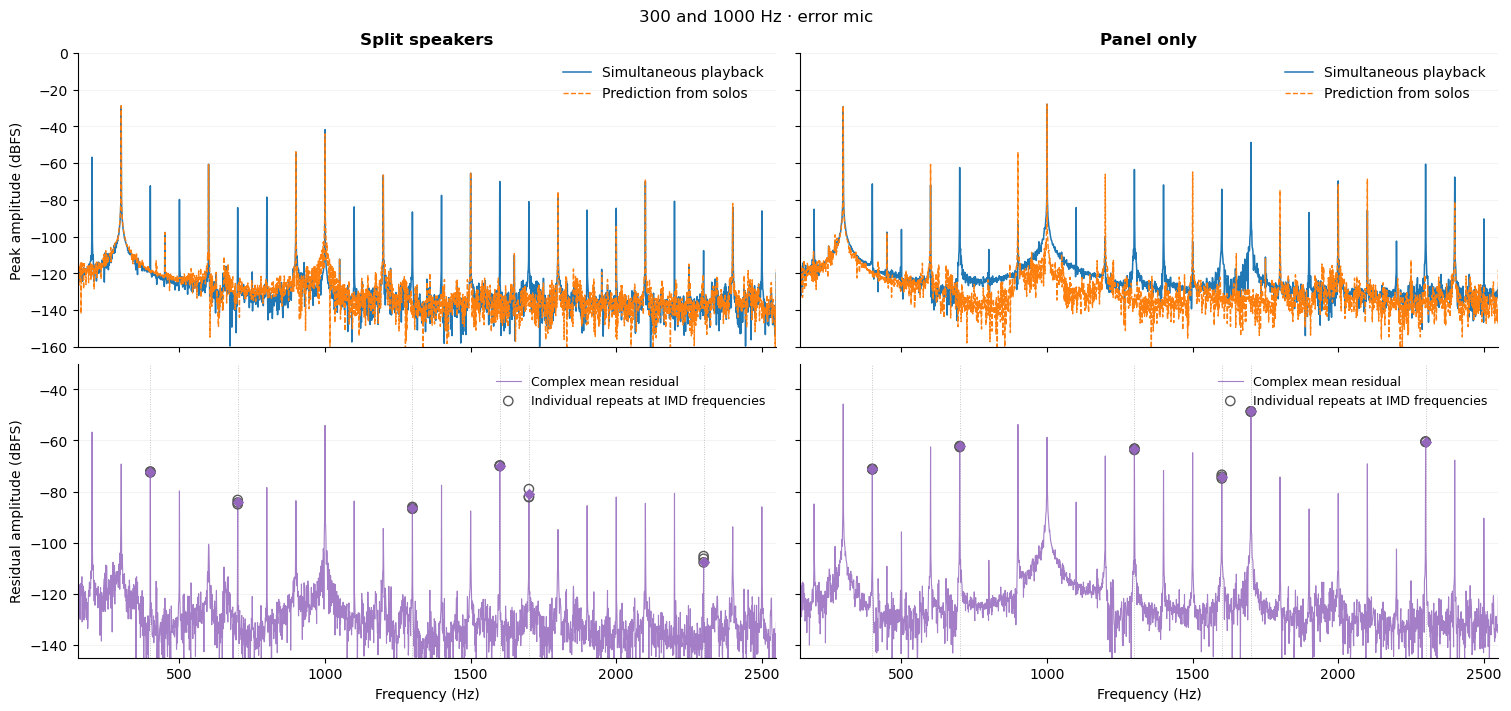

In [20]:
fig, axes = plt.subplots(
    2, 2, figsize=(15, 7), sharex=True, sharey="row",
    constrained_layout=True
)

fmin, fmax = 150, max(hz for _, hz in products) + 250
band = (freq >= fmin) & (freq <= fmax)
product_hz = np.array([hz for _, hz in products])
product_bins = np.rint(product_hz * n / fs).astype(int)
if (np.any(product_bins < 0) or np.any(product_bins >= len(freq))
        or not np.allclose(freq[product_bins], product_hz)):
    raise ValueError("Mixing frequencies must fall on valid FFT bins")

# Common residual limits across both tests. Clip only the displayed noise floor.
residual_floor = -145
residual_peak = max(float(np.max(dbfs(s["residual"][:, band])))
                    for s in spectra.values())
residual_ceiling = max(residual_floor + 20, 10 * np.ceil((residual_peak + 8) / 10))

for col, (test, s) in enumerate(spectra.items()):
    top, bottom = axes[:, col]
    r = s["residual"]
    mean_residual = r.mean(axis=0)

    top.plot(freq[band], dbfs(s["both"].mean(axis=0)[band]),
             lw=1.1, label="Simultaneous playback")
    top.plot(freq[band], dbfs(s["predicted"].mean(axis=0)[band]),
             lw=1, ls="--", color="tab:orange", label="Prediction from solos")
    top.set_title(titles[test], fontweight="bold")
    top.set_ylim(-160, 0)
    top.legend(loc="upper right", frameon=False)

    # One unsmoothed trace, with repeats shown only at the mixing frequencies.
    bottom.plot(freq[band], dbfs(mean_residual[band]),
                lw=0.8, color="tab:purple", alpha=0.85,
                label="Complex mean residual", zorder=2)
    for i, trial_spectrum in enumerate(r):
        bottom.scatter(product_hz, dbfs(trial_spectrum[product_bins]),
                       s=45, facecolors="none", edgecolors="0.35",
                       linewidths=1.0, zorder=4,
                       label="Individual repeats at IMD frequencies" if i == 0 else None)
    bottom.scatter(product_hz, dbfs(mean_residual[product_bins]),
                   s=24, marker="D", color="tab:purple", zorder=5)
    for hz in product_hz:
        bottom.axvline(hz, color="0.75", ls=":", lw=0.65, zorder=0)
    bottom.set_ylim(residual_floor, residual_ceiling)
    bottom.set_xlabel("Frequency (Hz)")
    bottom.legend(loc="upper right", frameon=False, fontsize=9)

    for ax in (top, bottom):
        ax.set_xlim(fmin, fmax)
        ax.grid(axis="y", alpha=0.15)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

axes[0, 0].set_ylabel("Peak amplitude (dBFS)")
axes[1, 0].set_ylabel("Residual amplitude (dBFS)")
fig.suptitle(f"{f1:g} and {f2:g} Hz · {mic_key.replace('_', ' ')}")
plt.show()


## Mixing-frequency residuals
Open circles show each repeat, spread horizontally for visibility. Diamonds show the magnitude of the complex mean. Vertical differences between circles show amplitude variation; phase variation can lower the diamond even when circle heights match.


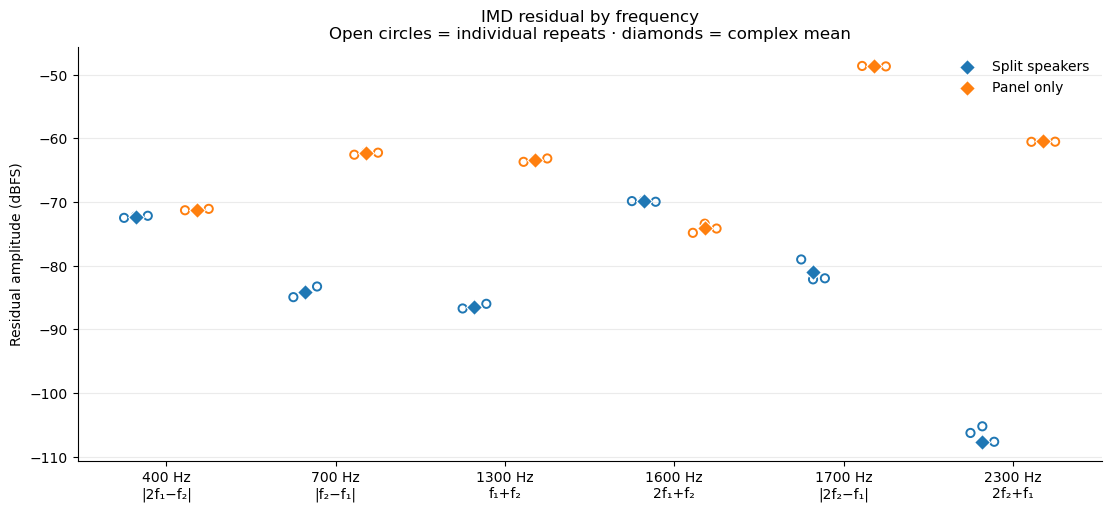

In [18]:
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(len(products))

for test, shift, color in [
    ("split_speakers", -0.18, "tab:blue"),
    ("panel_only",      0.18, "tab:orange"),
]:
    s = spectra[test]

    # Complex residuals: (repeats, frequency components)
    bins = []
    for name, hz in products:
        k = round(hz * n / fs)
        if not (0 <= k < len(freq)) or not np.isclose(freq[k], hz):
            raise ValueError(f"{hz:g} Hz is not on an FFT bin")
        bins.append(k)

    residuals = s["residual"][:, bins]

    # Convert each repeat separately to dBFS.
    levels = 20 * np.log10(np.maximum(np.abs(residuals), 1e-20))

    # Average in the complex domain BEFORE taking magnitude.
    mean_levels = 20 * np.log10(
        np.maximum(np.abs(residuals.mean(axis=0)), 1e-20)
    )

    num_repeats = residuals.shape[0]
    offsets = (
        np.linspace(-0.07, 0.07, num_repeats)
        if num_repeats > 1 else np.array([0.0])
    )

    for repeat, offset in enumerate(offsets):
        ax.scatter(
            x + shift + offset,
            levels[repeat],
            s=35,
            facecolors="none",
            edgecolors=color,
            linewidths=1.4,
            zorder=3,
        )

    ax.scatter(
        x + shift,
        mean_levels,
        color=color,
        marker="D",
        s=65,
        edgecolors="white",
        linewidths=0.8,
        label=titles[test],
        zorder=4,
    )

ax.set_xticks(x, [f"{hz:g} Hz\n{name}" for name, hz in products])
ax.set_ylabel("Residual amplitude (dBFS)")
ax.set_title(
    "IMD residual by frequency\n"
    "Open circles = individual repeats · diamonds = complex mean"
)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.show()

## Numerical values
The last two columns add/subtract SE in linear amplitude before converting to dBFS. They are radial bounds in the complex plane, not a confidence interval.


In [19]:
rows = []
for test, s in spectra.items():
    for component, hz in [("f₁", f1), ("f₂", f2)] + products:
        k = round(hz * n / fs)
        if not (0 <= k < len(freq)) or not np.isclose(freq[k], hz):
            raise ValueError(f"{hz:g} Hz is not on an FFT bin")
        r = s["residual"][:, k]
        mean_amp = abs(r.mean())
        se = repeat_se(r)
        row = {"test": titles[test], "component": component, "Hz": hz}
        for i, value in enumerate(r, start=1):
            row[f"repeat {i} dBFS"] = float(dbfs(value))
        row["complex mean dBFS"] = float(dbfs(mean_amp))
        # Radial bounds of a circle of radius SE in the complex plane.
        # These are not a conventional 68% amplitude confidence interval.
        row["mean minus SE dBFS"] = float(dbfs(mean_amp - se)) if mean_amp > se else -np.inf
        row["mean plus SE dBFS"] = float(dbfs(mean_amp + se))
        rows.append(row)
table = pd.DataFrame(rows)
display(table.round(3))


,test,component,Hz,repeat 1 dBFS,repeat 2 dBFS,repeat 3 dBFS,complex mean dBFS,mean minus SE dBFS,mean plus SE dBFS
0,Split speakers,f₁,300.0,-61.600,-80.223,-71.158,-69.212,-81.695,-64.290
1,Split speakers,f₂,1000.0,-53.752,-54.222,-54.236,-54.102,-54.698,-53.545
2,Split speakers,|2f₁−f₂|,400.0,-72.502,-72.260,-72.176,-72.312,-72.418,-72.207
3,Split speakers,|f₂−f₁|,700.0,-84.961,-84.273,-83.287,-84.171,-84.874,-83.521
4,Split speakers,f₁+f₂,1300.0,-86.738,-86.556,-86.007,-86.498,-87.354,-85.719
5,Split speakers,2f₁+f₂,1600.0,-69.871,-69.784,-69.973,-69.894,-70.304,-69.502
6,Split speakers,|2f₂−f₁|,1700.0,-79.037,-82.164,-81.999,-80.960,-82.174,-79.895
7,Split speakers,2f₂+f₁,2300.0,-106.296,-105.250,-107.681,-107.682,-112.617,-104.555
8,Panel only,f₁,300.0,-45.193,-46.074,-46.003,-45.748,-46.057,-45.450
9,Panel only,f₂,1000.0,-50.894,-67.133,-63.725,-58.769,-71.689,-53.789
